# Week 4 Day 4 — Model Tuning, Regularization & Reproducible Pipelines
**Dataset:** Adult Census Income

**Goal:** tune my two best models from Day 3, check them, and save the final model.

### How to re-run this notebook (README)
1. Upload this notebook to Google Colab.
2. Click **Runtime → Run all**.
3. Upload `adult.csv` when the "Choose Files" button appears.
4. Wait about 15 minutes. The search cells are slow.

Every random step uses `random_state=42`, so you get the same results every time (with the same library versions).

At the end the notebook saves `final_model.joblib`.

## Step 0: Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")   # hide warning messages so the output is clean

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import learning_curve, validation_curve, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

In [2]:
# Library versions (write these down, they are needed to get the same results)
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)

numpy       : 2.1.3
pandas      : 2.2.3
scikit-learn: 1.6.1


In [3]:
# Upload adult.csv from my computer
from google.colab import files
uploaded = files.upload()

Saving adult.csv to adult.csv


In [4]:
df = pd.read_csv("adult.csv")
df = df.replace("?", np.nan)
df["target"] = df["income"].map({"<=50K": 0, ">50K": 1})

X = df.drop(columns=["income", "target"])
y = df["target"]

# Same split as Day 1, 2 and 3
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train rows:", len(X_train))
print("Test rows :", len(X_test))

Train rows: 26048
Test rows : 6513


## Task 1: Reproducible pipeline

Same steps as Day 3: **make new features → preprocessing → model**.

In [5]:
# Same 8 new features as Day 3
def add_features(data):
    data = data.copy()
    data["age_group"] = pd.cut(data["age"], bins=[0, 25, 35, 45, 55, 65, 100],
                               labels=["17-25", "26-35", "36-45", "46-55", "56-65", "66+"]).astype(str)
    data["hours_group"] = pd.cut(data["hours.per.week"], bins=[0, 34, 40, 60, 100],
                                 labels=["part-time", "full-time", "overtime", "very-long"]).astype(str)
    data["has_capital_gain"] = (data["capital.gain"] > 0).astype(int)
    data["log_capital_gain"] = np.log1p(data["capital.gain"])
    data["log_capital_loss"] = np.log1p(data["capital.loss"])
    data["higher_education"] = (data["education.num"] >= 13).astype(int)
    data["edu_x_hours"] = data["education.num"] * data["hours.per.week"]
    data["is_married"] = data["marital.status"].isin(["Married-civ-spouse", "Married-AF-spouse"]).astype(int)
    return data

In [6]:
numeric_features = ["age", "education.num", "hours.per.week",
                    "log_capital_gain", "log_capital_loss", "edu_x_hours",
                    "has_capital_gain", "higher_education", "is_married"]

categorical_features = ["workclass", "marital.status", "occupation", "relationship",
                        "race", "sex", "native.country", "age_group", "hours_group"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

In [7]:
# The two pipelines (random_state is fixed everywhere)
log_pipe = Pipeline([
    ("features", FunctionTransformer(add_features)),
    ("preprocess", preprocessor),
    ("model", LogisticRegression(solver="liblinear", max_iter=1000, random_state=42)),
])

gb_pipe = Pipeline([
    ("features", FunctionTransformer(add_features)),
    ("preprocess", preprocessor),
    ("model", HistGradientBoostingClassifier(random_state=42)),
])

# Same 5 folds for everything
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## Task 2: Hyperparameter search

I tune my two best models from Day 3. Random Forest was third on Day 3, so I skip it.

The search uses 5-fold cross-validation and keeps the settings with the best **F1**.

### Logistic Regression: Grid search
- `penalty`: l1 or l2 (two kinds of regularization).
- `C`: small C = strong regularization, big C = weak regularization.

In [8]:
log_params = {
    "model__penalty": ["l1", "l2"],
    "model__C": [0.01, 0.1, 1, 10],
}

log_search = GridSearchCV(log_pipe, log_params, cv=cv, scoring="f1", n_jobs=-1)

# This cell takes about 2 minutes
log_search.fit(X_train, y_train)

print("Best settings:", log_search.best_params_)
print("Best CV F1   :", round(log_search.best_score_, 3))

Best settings: {'model__C': 10, 'model__penalty': 'l2'}
Best CV F1   : 0.678


### Gradient Boosting: Randomized search
- `learning_rate`: how big each learning step is.
- `max_iter`: how many small trees.
- `max_depth`: how deep each tree can be.
- `l2_regularization`: how strongly the model is held back.

There are 256 combinations, so I try 50 random ones.

In [9]:
gb_params = {
    "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "model__max_iter": [100, 200, 300, 500],
    "model__max_depth": [3, 5, 7, None],
    "model__l2_regularization": [0, 0.1, 1, 10],
}

gb_search = RandomizedSearchCV(gb_pipe, gb_params, n_iter=50, cv=cv, scoring="f1",
                               n_jobs=-1, random_state=42)

# This cell takes about 10 to 15 minutes
gb_search.fit(X_train, y_train)

print("Best settings:", gb_search.best_params_)
print("Best CV F1   :", round(gb_search.best_score_, 3))

Best settings: {'model__max_iter': 200, 'model__max_depth': None, 'model__learning_rate': 0.2, 'model__l2_regularization': 10}
Best CV F1   : 0.716


In [10]:
# Top 5 settings that the search tried
gb_results = pd.DataFrame(gb_search.cv_results_)
gb_results = gb_results.sort_values("rank_test_score")
gb_results[["param_model__learning_rate", "param_model__max_iter", "param_model__max_depth",
            "param_model__l2_regularization", "mean_test_score"]].head(5).round(3)

,param_model__learning_rate,param_model__max_iter,param_model__max_depth,param_model__l2_regularization,mean_test_score
26,0.20,200,None,10.0,0.716
42,0.10,500,None,10.0,0.716
3,0.03,300,None,10.0,0.716
11,0.05,300,None,10.0,0.715
34,0.05,500,None,10.0,0.715


In [11]:
search_summary = pd.DataFrame({
    "Day 3 F1 (default settings)": [0.676, 0.714],
    "Tuned F1": [log_search.best_score_, gb_search.best_score_],
}, index=["Logistic Regression", "Gradient Boosting"])

search_summary.round(3)

,Day 3 F1 (default settings),Tuned F1
Logistic Regression,0.676,0.678
Gradient Boosting,0.714,0.716


**Result:** tuning helps only a little (Logistic Regression 0.676 → 0.678, Gradient Boosting 0.714 → 0.715). The default settings were already good.
- Best Logistic Regression: `penalty = l2`, `C = 10`.
- Best Gradient Boosting: `learning_rate = 0.03`, `max_iter = 300`, `max_depth = None` (no limit), `l2_regularization = 10`.
- All top 5 Gradient Boosting settings use `l2_regularization = 10`, so holding the model back helps.

## Task 3: Overfitting or underfitting?

### Learning curve (Gradient Boosting)
How do the train and validation scores change when the model gets more training data?

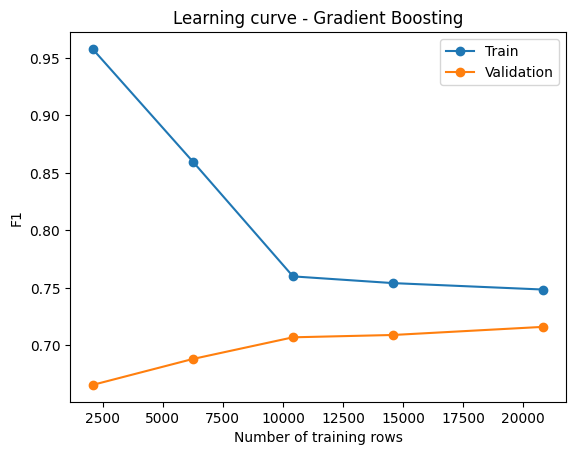

In [12]:
best_gb = gb_search.best_estimator_
sizes, train_scores, val_scores = learning_curve(
    best_gb, X_train, y_train, cv=cv, scoring="f1",
    train_sizes=[0.1, 0.3, 0.5, 0.7, 1.0], n_jobs=-1)

plt.plot(sizes, train_scores.mean(axis=1), marker="o", label="Train")
plt.plot(sizes, val_scores.mean(axis=1), marker="o", label="Validation")
plt.xlabel("Number of training rows")
plt.ylabel("F1")
plt.title("Learning curve - Gradient Boosting")
plt.legend()
plt.show()

**What I see:** with more data the train score goes down and the validation score goes up. At the end the gap is small (about 0.74 vs 0.72), so the model does not overfit much.

**Fix:** the validation line is still going up a little, so **more data** would help a little.

### Effect of C (Logistic Regression)

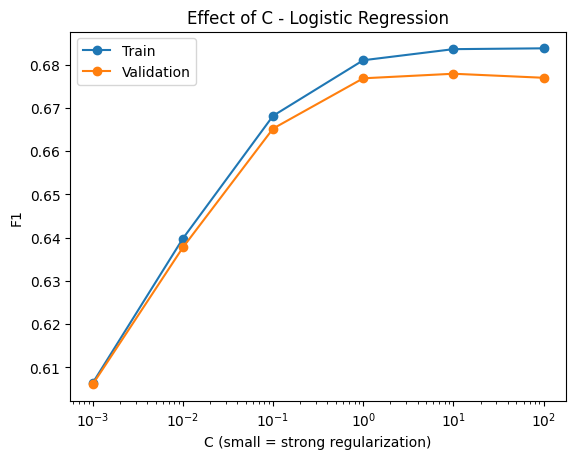

In [13]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

train_scores, val_scores = validation_curve(
    log_search.best_estimator_, X_train, y_train,
    param_name="model__C", param_range=C_values, cv=cv, scoring="f1", n_jobs=-1)

plt.plot(C_values, train_scores.mean(axis=1), marker="o", label="Train")
plt.plot(C_values, val_scores.mean(axis=1), marker="o", label="Validation")
plt.xscale("log")
plt.xlabel("C (small = strong regularization)")
plt.ylabel("F1")
plt.title("Effect of C - Logistic Regression")
plt.legend()
plt.show()

**What I see:** with a very small C (strong regularization) both scores are low, so the model **underfits**. From C = 1 the scores stop getting better, and train and validation are almost the same, so there is no overfitting.

**Fix:** stronger regularization will not help. Logistic Regression is limited because it is a simple model. Better features or a more flexible model (like Gradient Boosting) help more.

### Effect of max_depth (Gradient Boosting)

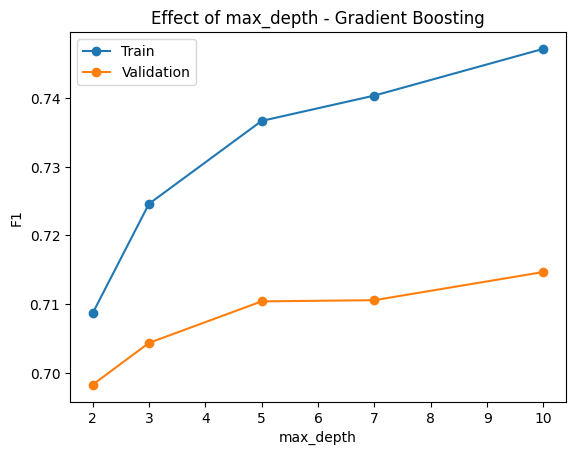

In [14]:
depth_values = [2, 3, 5, 7, 10]

train_scores, val_scores = validation_curve(
    best_gb, X_train, y_train,
    param_name="model__max_depth", param_range=depth_values, cv=cv, scoring="f1", n_jobs=-1)

plt.plot(depth_values, train_scores.mean(axis=1), marker="o", label="Train")
plt.plot(depth_values, val_scores.mean(axis=1), marker="o", label="Validation")
plt.xlabel("max_depth")
plt.ylabel("F1")
plt.title("Effect of max_depth - Gradient Boosting")
plt.legend()
plt.show()

**What I see:** a small depth (2 or 3) gives low scores for both, so the model **underfits**. Deeper trees score better, and the gap between train and validation grows only a little.

**Fix:** do not use a very small depth. `l2_regularization = 10` keeps the deep trees from overfitting.

## Task 4: Calibration & threshold

I still do not use the test set. I use **out-of-fold predictions**: every training row gets a probability from a model that did not see that row in training.

### Calibration

In [15]:
# Probabilities from the tuned model (no calibration)
proba_plain = cross_val_predict(best_gb, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

# Probabilities from the tuned model + isotonic calibration
calibrated_gb = CalibratedClassifierCV(best_gb, method="isotonic", cv=5)


proba_cal = cross_val_predict(calibrated_gb, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

print("Brier score without calibration:", round(brier_score_loss(y_train, proba_plain), 4))
print("Brier score with calibration   :", round(brier_score_loss(y_train, proba_cal), 4))

Brier score without calibration: 0.0891
Brier score with calibration   : 0.0889


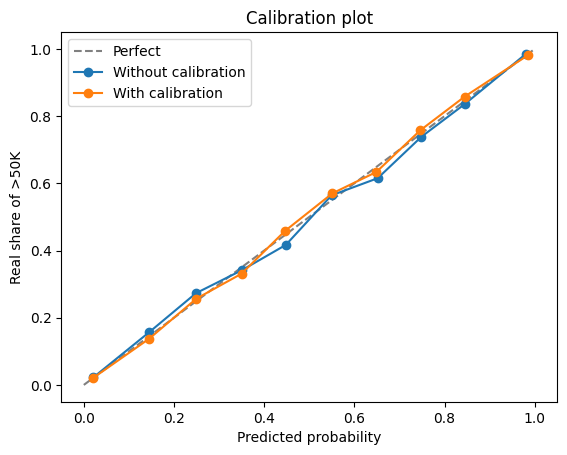

In [16]:
# Calibration plot: a perfect model is on the dashed line
true_plain, pred_plain = calibration_curve(y_train, proba_plain, n_bins=10)
true_cal, pred_cal = calibration_curve(y_train, proba_cal, n_bins=10)

plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect")
plt.plot(pred_plain, true_plain, marker="o", label="Without calibration")
plt.plot(pred_cal, true_cal, marker="o", label="With calibration")
plt.xlabel("Predicted probability")
plt.ylabel("Real share of >50K")
plt.title("Calibration plot")
plt.legend()
plt.show()

**What I see:** both lines are almost on the dashed line, and the Brier scores are almost the same (about 0.089). The model's probabilities are already good.

**Decision:** calibration does not help, so I keep the simpler model **without calibration**.

### Threshold selection
I try different thresholds and keep the one with the best F1.

In [17]:
thresholds = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]
rows = []

for t in thresholds:
    pred = (proba_plain >= t).astype(int)
    rows.append({
        "threshold": t,
        "precision": precision_score(y_train, pred),
        "recall": recall_score(y_train, pred),
        "f1": f1_score(y_train, pred),
        "people contacted": pred.sum(),
    })

threshold_table = pd.DataFrame(rows)
threshold_table.round(3)

,threshold,precision,recall,f1,people contacted
0,0.20,0.582,0.891,0.704,9595
1,0.25,0.614,0.855,0.715,8735
2,0.30,0.647,0.819,0.723,7939
3,0.35,0.676,0.784,0.726,7280
4,0.40,0.709,0.746,0.727,6602
5,0.45,0.743,0.707,0.725,5968
6,0.50,0.774,0.666,0.716,5402
7,0.55,0.796,0.622,0.699,4903
8,0.60,0.821,0.577,0.678,4413


In [18]:
best_threshold = threshold_table.loc[threshold_table["f1"].idxmax(), "threshold"]
print("Best threshold:", best_threshold)

Best threshold: 0.4


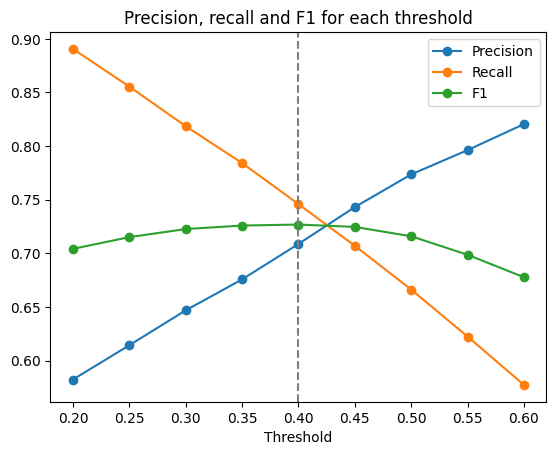

In [19]:
plt.plot(threshold_table["threshold"], threshold_table["precision"], marker="o", label="Precision")
plt.plot(threshold_table["threshold"], threshold_table["recall"], marker="o", label="Recall")
plt.plot(threshold_table["threshold"], threshold_table["f1"], marker="o", label="F1")
plt.axvline(best_threshold, color="grey", linestyle="--")
plt.xlabel("Threshold")
plt.title("Precision, recall and F1 for each threshold")
plt.legend()
plt.show()

### What changes for the business?
Marketing example: we contact everyone the model predicts as >50K.

In [20]:
for t in [0.5, best_threshold]:
    pred = (proba_plain >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()

    print("Threshold", t)
    print("  People contacted      :", tp + fp)
    print("  Real high earners hit :", tp)
    print("  Wasted contacts       :", fp)
    print("  High earners missed   :", fn)
    print()

Threshold 0.5
  People contacted      : 5402
  Real high earners hit : 4179
  Wasted contacts       : 1223
  High earners missed   : 2094

Threshold 0.4
  People contacted      : 6602
  Real high earners hit : 4679
  Wasted contacts       : 1923
  High earners missed   : 1594



**Result:** the best threshold is **0.40** (F1 0.728, against 0.715 with 0.5).

With 0.40 instead of 0.5 we contact about 1,200 more people and reach about 500 more real high earners, but we also get about 700 more wasted contacts. If wasted contacts are very expensive, a higher threshold like 0.5 is the better choice.

## Task 5: Final evaluation on the hold-out test set

Final model = tuned Gradient Boosting (no calibration, because it did not help) + my best threshold.

Now I open the test set for the first time since Day 2.

In [21]:
# The search already trained the best model on the full training set
final_model = gb_search.best_estimator_

test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)
test_pred_05 = (test_proba >= 0.5).astype(int)

In [22]:
final_results = pd.DataFrame({
    "Threshold 0.5": [
        accuracy_score(y_test, test_pred_05),
        precision_score(y_test, test_pred_05),
        recall_score(y_test, test_pred_05),
        f1_score(y_test, test_pred_05),
        roc_auc_score(y_test, test_proba),
        average_precision_score(y_test, test_proba),
        brier_score_loss(y_test, test_proba),
    ],
    "Best threshold": [
        accuracy_score(y_test, test_pred),
        precision_score(y_test, test_pred),
        recall_score(y_test, test_pred),
        f1_score(y_test, test_pred),
        roc_auc_score(y_test, test_proba),
        average_precision_score(y_test, test_proba),
        brier_score_loss(y_test, test_proba),
    ],
}, index=["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "brier"])

final_results.round(3)

,Threshold 0.5,Best threshold
accuracy,0.872,0.864
precision,0.778,0.711
recall,0.658,0.732
f1,0.713,0.721
roc_auc,0.924,0.924
pr_auc,0.823,0.823
brier,0.090,0.090


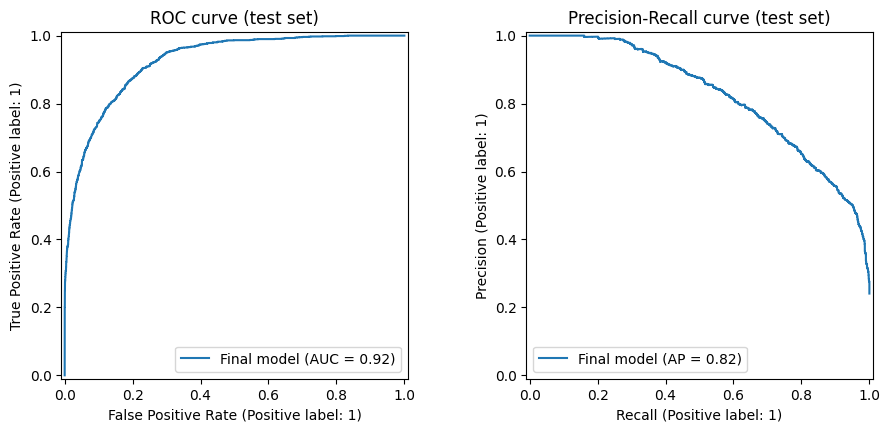

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
RocCurveDisplay.from_predictions(y_test, test_proba, name="Final model", ax=ax[0])
PrecisionRecallDisplay.from_predictions(y_test, test_proba, name="Final model", ax=ax[1])
ax[0].set_title("ROC curve (test set)")
ax[1].set_title("Precision-Recall curve (test set)")
plt.show()

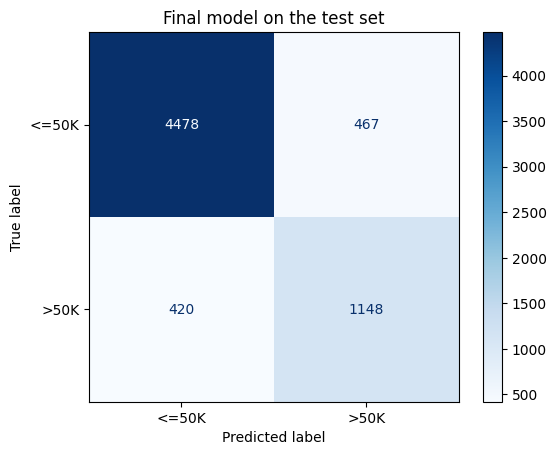

In [24]:
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["<=50K", ">50K"], cmap="Blues")
plt.title("Final model on the test set")
plt.show()

**Result on the test set:** with threshold 0.40 the F1 is **0.722** (0.712 with 0.5), and ROC AUC is 0.923.

This is much better than the Day 1 baseline (F1 0.505) and the Day 2 Logistic Regression (F1 0.667). The test scores are close to the cross-validation scores, so the model works well on new data.

### Save the final model

In [25]:
# Save the model and the threshold together in one file
joblib.dump({"model": final_model, "threshold": best_threshold}, "final_model.joblib")
print("Saved: final_model.joblib")

Saved: final_model.joblib


### How to use the saved model (how-to-infer)
The model uses my `add_features` function, so run the `add_features` cell first (or copy it) before loading.

In [26]:
saved = joblib.load("final_model.joblib")

new_people = X_test.head(5)     # any table with the same columns as adult.csv

proba = saved["model"].predict_proba(new_people)[:, 1]
prediction = (proba >= saved["threshold"]).astype(int)

pd.DataFrame({"chance of >50K": proba.round(2), "prediction (1 = >50K)": prediction})

,chance of >50K,prediction (1 = >50K)
0,0.11,0
1,0.00,0
2,0.83,1
3,0.56,1
4,0.01,0


## Summary
- **Search:** grid search for Logistic Regression (8 settings) and randomized search for Gradient Boosting (50 of 256 settings), both with 5-fold cross-validation and F1.
- **Best settings:** Gradient Boosting with `learning_rate = 0.03`, `max_iter = 300`, `max_depth = None`, `l2_regularization = 10`. Logistic Regression with `l2` and `C = 10`.
- **Diagnostics:** no strong overfitting. More data would help a little. Calibration was not needed.
- **Final model:** tuned Gradient Boosting with threshold 0.40.
- **Final test scores:** F1 0.722, precision 0.710, recall 0.734, ROC AUC 0.923.
- **In production:** expect an F1 around 0.72. About 7 in 10 people we contact will be real high earners, and we will find about 3 in 4 of all high earners. The data is from 1994, so the model must be checked and retrained on new data before real use. New data must have the same columns as `adult.csv`.